In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.integrate import simpson
import os

from itertools import product

In [2]:
### Emergency Hover and Propeller Sizing ###
# max thrust should allow one engine to hover the aircraft such that V_y = 0
def max_thrust(mass, acc, g): # total thrust 
    return mass * g

def propeller_sizing(T_Max, density, V_e, delta_pressure): # assuming in test bed or during single engine hover
    T_prop_gross = T_Max * 0.95 # assuming 95% of thrust comes from the prop
    Area = T_prop_gross / (delta_pressure + 0.5 * density * V_e ** 2)
    return np.sqrt(4 * Area / np.pi)

def prop_max_power(T_Max, density, prop_eff, dp):
    return np.sqrt((2 * (T_Max ** 3)) / (np.pi * density * prop_eff**2 * dp**2))
    
max_weight = 19000 #kg
gravity = 9.81 #m/s^2
downwards_acc = 0.5
acc = np.linspace(0.1, 5, 500)
height = 1500 #m, roughly 5k ft
air_density = 1.05 #  np.linspace(1.05, 1.225, 100) # range between sea level to 1500 m

# takeoff_kinematics(acc, height)
thrust_maximum = max_thrust(max_weight, downwards_acc, gravity)
prop_diameter = propeller_sizing(thrust_maximum, air_density, 20, 1500)
P = prop_max_power(thrust_maximum, air_density, 0.80, prop_diameter)

print(f"T_max = {thrust_maximum}, D_p = {prop_diameter}, P = {P}")

T_max = 186390.0, D_p = 11.48233229171348, P = 6821175.547382889


In [3]:
def ISA_atmosphere(altitude):
    g = 9.81 # m/s^2
    R = 8.314 # J/(mol K)
    M = 0.02896 # kg/mol
    P0 = 101325.0 # Pa
    T0 = 288.15 # K
    L = 0.0065 # K/m, temperature gradient w.r.t alt

    altitude = np.asarray(altitude)
    T = T0 - (L * altitude)
    P = P0 * (1 - (L * altitude) / T0) ** (g * M / (R * L))
    rho = (P * M) / (R * T)
    
    return P, T, rho

def isentropic_calc(p_in, T_in, pressure_ratio, gamma, turbo):
    if turbo == "comp":
        return p_in * pressure_ratio, T_in * pressure_ratio ** ((gamma-1) / gamma)
    elif turbo == "turb":
        return p_in / pressure_ratio, T_in / (pressure_ratio ** ((gamma-1) / gamma))

def enthalpy_calc(Cp, T_high, T_low):
    return abs(Cp * (T_high - T_low))

def compressor(p1, T1, pressure_ratio, gamma, Cp):
    p2, T2 = isentropic_calc(p1, T1, pressure_ratio, gamma, "comp")
    work = 0.85 * enthalpy_calc(Cp, T2, T1)
    return work, p2, T2

def combustor(target_T3, T2, P2, pressure_loss, Cp):
    heat = enthalpy_calc(Cp, target_T3, T2)
    return heat, P2 * pressure_loss

def turbine(p3, target_T3, pressure_ratio, gamma, Cp):
    p4, T4 = isentropic_calc(p3, target_T3, pressure_ratio, gamma, "turb")
    work = 0.89 * enthalpy_calc(Cp, target_T3, T4)
    return work, p4, T4

def brayton_cycle_analysis(alt_list, tit_list, pr_list):
    gamma_c, Cp_c = 1.4, 1.005
    gamma_h, Cp_h = 1.33, 1.15
    combustor_eff = 0.95
    results = []

    for altitude, T3, pressure_ratio in product(alt_list, tit_list, pr_list):
        P1, T1, rho1 = ISA_atmosphere(altitude)
        work_comp, P2, T2 = compressor(P1, T1, pressure_ratio, gamma_c, Cp_c)
        heat_in, P3 = combustor(T3, T2, P2, combustor_eff, Cp_h)
        expansion_ratio = P3 / P1
        work_turb, P4, T4 = turbine(P3, T3, expansion_ratio, gamma_h, Cp_h)

        work_net = work_turb - work_comp
        sfc = (heat_in / work_net) * 3.6e6 / 43.1e6

        results.append({
            "Cruise_Altitude": altitude,
            "TIT (K)": T3,
            "PR": pressure_ratio,
            "Availabe Specific Propeller Power (kJ / kg)": work_net,
            "Heat In (kJ / kg)": heat_in,
            "SFC (kg / kWh)": sfc,
            "Inlet Air Density (kg/m^3)": rho1
        })
        
    return pd.DataFrame(results)

def performance_plot(df, design_altitude):
    subset = df[df['Cruise_Altitude'] == design_altitude].copy()
    plt.style.use('bmh')
    fig = plt.figure(figsize=(18, 12))
    plt.suptitle(f"Engine Cycle Performance @ {design_altitude}m Altitude", fontsize=16)

    # Pressure Ratio vs. SFC
    ax1 = fig.add_subplot(2, 2, 1)
    scatter1 = ax1.scatter(
        subset['PR'], 
        subset['SFC (kg / kWh)'], 
        c=subset['TIT (K)'], 
        cmap='inferno', 
        s=50, 
        edgecolor='k'
    )
    ax1.set_xlabel("Pressure Ratio")
    ax1.set_ylabel("SFC (kg/kWh)")
    ax1.set_title("Pressure Ratio and Turbine Inlet Temperature Effects on SFC")
    fig.colorbar(scatter1, ax=ax1, label='TIT (K)')
    ax1.grid(True, linestyle='--', alpha=0.7)

    # Design Space Heatmap (TIT vs PR)
    ax2 = fig.add_subplot(2, 2, 2)
    pivot_table = subset.pivot_table(values='SFC (kg / kWh)', index='TIT (K)', columns='PR')
    contour = ax2.contourf(
        pivot_table.columns, 
        pivot_table.index, 
        pivot_table.values, 
        levels=20, 
        cmap='RdYlGn_r'
    )
    ax2.set_xlabel("Pressure Ratio")
    ax2.set_ylabel("Turbine Inlet Temp (K)")
    ax2.set_title("Iso-SFC Contours (Green is Better)")
    fig.colorbar(contour, ax=ax2, label='SFC (kg/kWh)')


    # (Specific Power vs. SFC)
    ax3 = fig.add_subplot(2, 1, 2)
    tits = sorted(subset['TIT (K)'].unique())
    for t in tits:
        line_data = subset[subset['TIT (K)'] == t]
        ax3.plot(line_data['Availabe Specific Propeller Power (kJ / kg)'], 
                line_data['SFC (kg / kWh)'], 
                color='black', linestyle='-', linewidth=1, alpha=0.5)
        ax3.text(line_data['Availabe Specific Propeller Power (kJ / kg)'].iloc[-1], 
                line_data['SFC (kg / kWh)'].iloc[-1], 
                f'TIT={t}K', fontsize=9)

    prs = sorted(subset['PR'].unique())
    for p in prs:
        if p % 2 == 0: 
            line_data = subset[subset['PR'] == p]
            ax3.plot(line_data['Availabe Specific Propeller Power (kJ / kg)'], 
                    line_data['SFC (kg / kWh)'], 
                    color='blue', linestyle='--', linewidth=0.8, alpha=0.5)
    scatter3 = ax3.scatter(
        subset['Availabe Specific Propeller Power (kJ / kg)'], 
        subset['SFC (kg / kWh)'], 
        c=subset['TIT (K)'], 
        cmap='inferno', 
        s=60, 
        zorder=3
    )

    ax3.set_xlabel("Specific Shaft Power (kW / kg/s)")
    ax3.set_ylabel("SFC (kg/kWh)")
    ax3.set_title("Specific Shaft Power vs SFC")
    ax3.invert_yaxis() 
    fig.colorbar(scatter3, ax=ax3, label='TIT (K)')

    plt.tight_layout()
    plt.show()

def prop_sizing(required_shaft_power, cycle_data, density, v_face):
    sp_power = cycle_data['Available Specific Propeller Power (kJ / kg)']
    mdot_req = required_shaft_power / sp_power
    area = mdot_req / (density * v_face)
    diameter = 2 * np.sqrt(area / np.pi)
    
    return mdot_req, diameter

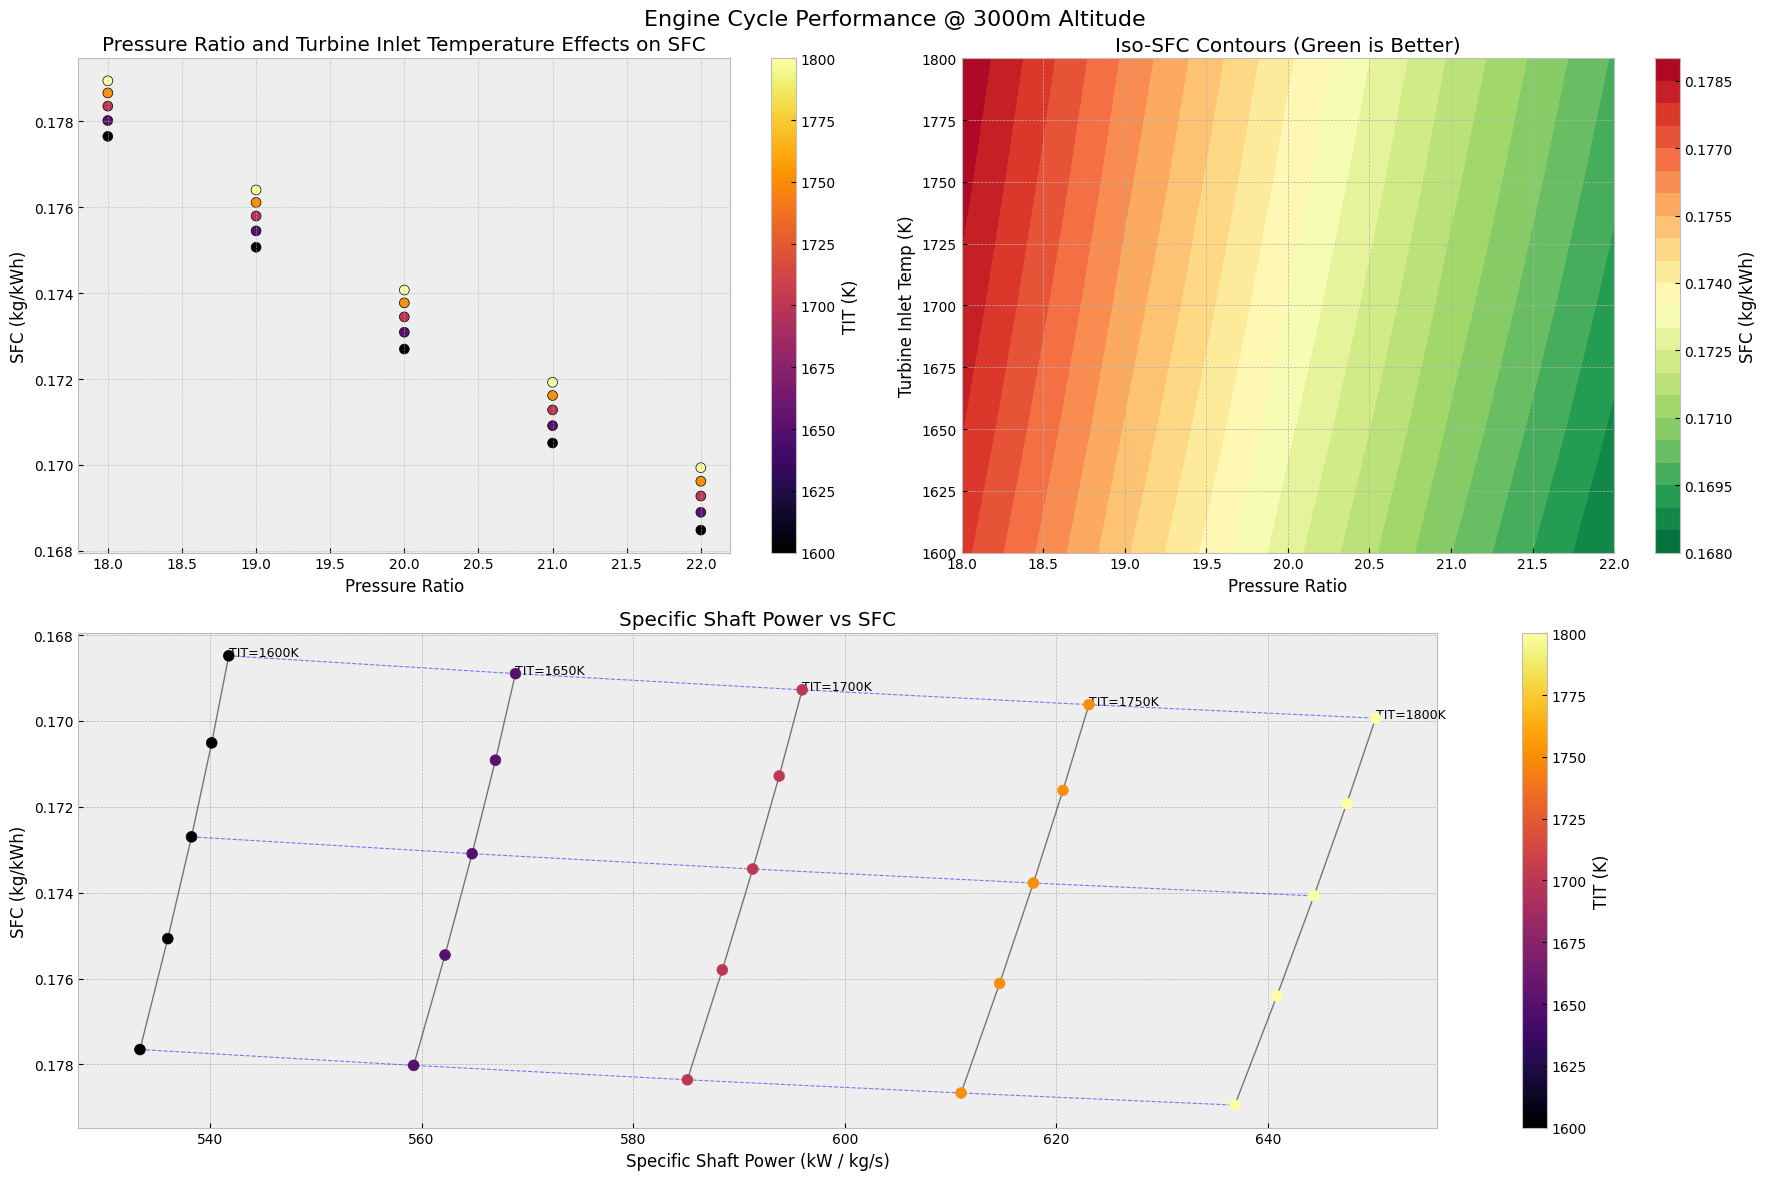

,Cruise_Altitude,TIT (K),PR,Availabe Specific Propeller Power (kJ / kg),Heat In (kJ / kg),SFC (kg / kWh),Inlet Air Density (kg/m^3),Required Air Massflow (kg/s)
1429,3000,1600,22,541.770943,1092.804887,0.168481,0.908942,12.590516
1434,3000,1650,22,568.874465,1150.304887,0.168897,0.908942,11.990652
1439,3000,1700,22,595.977987,1207.804887,0.169275,0.908942,11.445348
1444,3000,1750,22,623.081509,1265.304887,0.169619,0.908942,10.947485
1449,3000,1800,22,650.185031,1322.804887,0.169935,0.908942,10.491130
1428,3000,1600,21,540.156758,1102.670472,0.170511,0.908942,12.628141
1433,3000,1650,21,566.980824,1160.170472,0.170914,0.908942,12.030699
1438,3000,1700,21,593.804890,1217.670472,0.171282,0.908942,11.487234
1443,3000,1750,21,620.628956,1275.170472,0.171617,0.908942,10.990747
1448,3000,1800,21,647.453021,1332.670472,0.171925,0.908942,10.535398


In [4]:
alt_list = np.arange(150, 3100, 50)
temp_list = np.arange(1600, 1850, 50)
pressure_ratio_list = np.arange(18, 23, 1)

df = brayton_cycle_analysis(alt_list, temp_list, pressure_ratio_list)
performance_plot(df, alt_list[-2])

df["Required Air Massflow (kg/s)"] = P / (1000 * df['Availabe Specific Propeller Power (kJ / kg)'])
mask = (df["Required Air Massflow (kg/s)"] >= 11.5) & (df["Required Air Massflow (kg/s)"] <= 13.0)
df[(df['Cruise_Altitude'] == 3000)].sort_values(by="SFC (kg / kWh)")

In [5]:
Alt_H = np.array([0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 
         1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900,
         2000, 2100, 2200, 2300, 2400, 2500, 2600, 2700, 2800, 2900,
         3000, 3100, 3200, 3300, 3400, 3500, 3600, 3700, 3800, 3900,
         4000, 4100, 4200, 4300, 4400, 4500, 4600, 4700, 4800, 4900,
         5000, 5100, 5200, 5300, 5400, 5500, 5600, 5700, 5800, 5900,
         6000, 6100, 6200, 6300, 6400, 6500, 6600, 6700, 6800, 6900,
         7000, 7100, 7200, 7300, 7400, 7500, 7600, 7700, 7800, 7900,
         8000, 8100, 8200, 8300, 8400, 8500, 8600, 8700, 8800, 8900,
         9000, 9100, 9200, 9300, 9400, 9500, 9600, 9700, 9800, 9900,
         10000])

Alt_temp = np.array([288.150,287.952, 287.754, 287.556, 287.358,287.160,286.961, 286.763, 286.565, 286.367,
            286.169,285.971, 285.773, 285.575, 285.377,285.178,284.980, 284.782, 284.584, 284.386,
            284.188,283.990, 283.792, 283.595, 283.397,283.197,282.999, 282.801, 282.603, 282.405,
            282.207,282.008, 281.810, 281.612, 281.414,281.216,281.018, 280.820, 280.622, 280.424,
            280.225,280.027, 279.829, 279.631, 279.433,279.235,279.037, 278.839, 278.640, 278.442,
            278.244,278.046, 277.848, 277.650, 277.452,277.254,277.055, 276.857, 276.659, 276.461,
            276.263,276.065, 275.867, 275.669, 275.471,275.272,275.074, 274.876, 274.678, 274.480,
            274.282,274.084, 273.886, 273.687, 273.489,273.291,273.093, 272.895, 272.697, 272.499,
            272.301,272.102, 271.904, 271.706, 271.508,271.310,271.112, 270.914, 270.716, 270.518,
            270.319,270.121, 269.923, 269.725, 269.527,269.329,269.131, 268.933, 268.734, 268.536,
            268.338])


Alt_rho = np.array([1.2250,1.2214, 1.2178, 1.2143, 1.2107, 1.2072, 1.2036, 1.2001, 1.1966, 1.1931,
          1.1896, 1.1861, 1.1826, 1.1791, 1.1756, 1.1721, 1.1687, 1.1652, 1.1618, 1.1583,
          1.1549, 1.1515, 1.1481, 1.1447, 1.1413, 1.1379, 1.1345, 1.1311, 1.1277, 1.1244,
          1.1210, 1.1177, 1.1144, 1.1110, 1.1077, 1.1044, 1.1011, 1.0978, 1.0945, 1.0912,
          1.0879, 1.0847, 1.0814, 1.0781, 1.0749, 1.0717, 1.0684, 1.0652, 1.0620, 1.0588,
          1.0556, 1.0524, 1.0492, 1.0460, 1.0429, 1.0397, 1.0365, 1.0334, 1.0302, 1.0271,
          1.0240, 1.0209, 1.0178, 1.0146, 1.0115, 1.0085, 1.0054, 1.0023, 0.99923, 0.99617,
           0.99304, 0.98999, 0.98695, 0.98391, 0.98089, 0.97787, 0.97485, 0.97185, 0.96885, 
           0.96586, 0.96287, 0.95989, 0.95692, 0.95396, 0.95100, 0.94805, 0.94511, 0.94217, 
           0.93924, 0.93632, 0.93341, 0.93050, 0.92760, 0.92470, 0.92182, 0.91894, 0.91606, 
           0.91320, 0.91034, 0.90748, 0.90464])

5.3413940334257255 0.49188558552107897 0.09208936514380424 0.3915477227370946


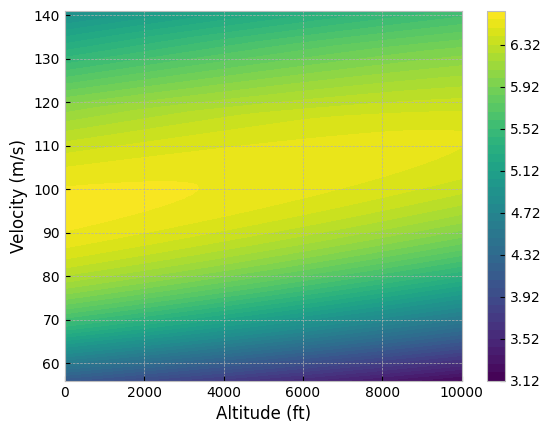

6.595041005525542
39.0
56.0


In [6]:
## L/D calculations ##

def get_LD(altitude,velocity,weight):
    
    Temp = np.interp(altitude, Alt_H, Alt_temp)
    sp_sound = np.sqrt(1.4*287*Temp)
    M = velocity/sp_sound

    Mach_nos = np.array([0.2,0.35,0.4,0.5,0.6])
    C_d0s = np.array([0.0684,0.0686112,0.069598,0.0746,0.088328])
    ks = np.array([0.08,0.087,0.095,0.115,0.22])

    C_d0_out = np.interp(M, Mach_nos, C_d0s)
    #print(C_d0_out)
    k_out = np.interp(M, Mach_nos, ks)
    #print(k_out)

    gravity = 9.81 #m/s^2
    wing_area = 35.49 # m^2
    density = np.interp(altitude, Alt_H, Alt_rho)
    C_L = (weight*gravity) / (0.5 * density * wing_area * (velocity**2))

    LD = C_L / (C_d0_out + k_out*(C_L**2))

    C_D = C_d0_out + k_out*(C_L**2)

    return LD, C_L, C_D, M

search_speed = 93 # m/s
cruise_speed = 133 # m/s

LD, C_L, C_D, M = get_LD(500,cruise_speed,19000)
print (LD, C_L, C_D, M)

def LD_max():
    altitude = np.linspace(0,10000,10001)
    velocity = np.linspace(56,141,86)
    alt, vel = np.meshgrid(altitude,velocity)
    LD, C_L, C_D, M = get_LD(alt,vel,19000)
    idx = np.unravel_index(np.argmax(LD), LD.shape)
    alt_opt = altitude[idx[0]]
    vel_opt = velocity[idx[1]]
    fig,ax = plt.subplots()
    plt.contourf(altitude,velocity,LD,levels=50)
    plt.ylabel("Velocity (m/s)")
    plt.xlabel("Altitude (ft)")
    plt.colorbar()
    plt.show()
    print(np.max(LD))
    print(alt_opt)
    print(vel_opt)

LD_max()

237.99999999999997

--- Main Propeller Design ---
Prop Diameter: 11.60 m
Single Engine Failure RPM: 392 RPM
Induced Wash (v_i): 27.11 m/s
Max Tip Speed:  238.0 m/s (Mach 0.7)
Root Chord, Ideal:     3.781 m
Root Chord, Real:     0.850 m
Tip Chord, Ideal:      0.569 m
Tip Chord, Real:      0.569 m

--- Forward Integration Results ---
Target Thrust:      186.4 kN
Ideal Blade Thrust: 184.5 kN
Practical Thrust:   160.2 kN
Thrust Penalty:     24.4 kN (13.20%)


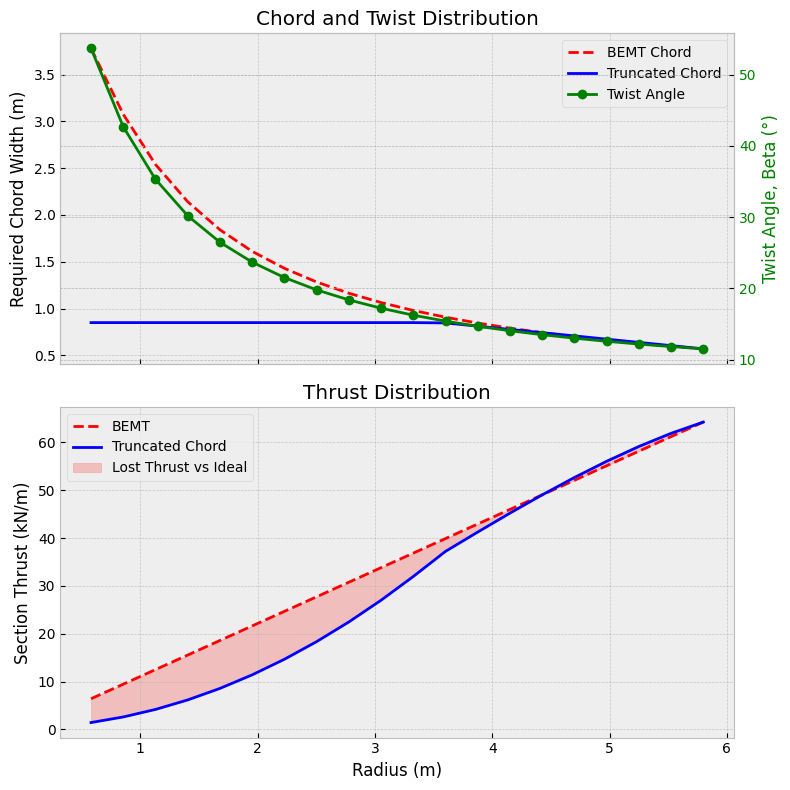


--- Cruise Propeller Design (3000 m) ---
Target V_inf:      133.0 m/s (Mach 0.405)
Cruise RPM:   312 RPM (Reduced from Hover to keep Mach 0.7)
Total Tip Speed:   187.6 m/s (Mach 0.5710755987589125)
Air Density:       0.909 kg/m^3

--- Variable Pitch Mechanism ---
75% Station Cruise Angle: 47.9 deg
75% Station Hover Angle:  13.5 deg
Required Pitch Shift: -34.4 degrees (Cruise -> Hover)

--- Search Propeller Design (150 m) ---
Target V_inf:      93.0 m/s (Mach 0.274)
Search RPM:   364 RPM (Reduced from Hover to keep Mach 0.7)
Total Tip Speed:   218.8 m/s (Mach 0.6442386932520948)
Air Density:       1.207 kg/m^3

--- Variable Pitch Mechanism ---
75% Station Cruise Angle: 34.1 deg
75% Station Hover Angle:  13.5 deg
Required Pitch Shift: -20.6 degrees (Search -> Hover)

--- Final OEI Hover Aerodynamic Evaluation ---
Target Thrust:                 186.4 kN
1. Ideal BEMT Thrust:     188.3 kN
2. Target Twist Angle:  163.5 kN (-13.2% loss)
3. Cruise Twist Angle + Pitch:   186.6 kN (-0.9% total

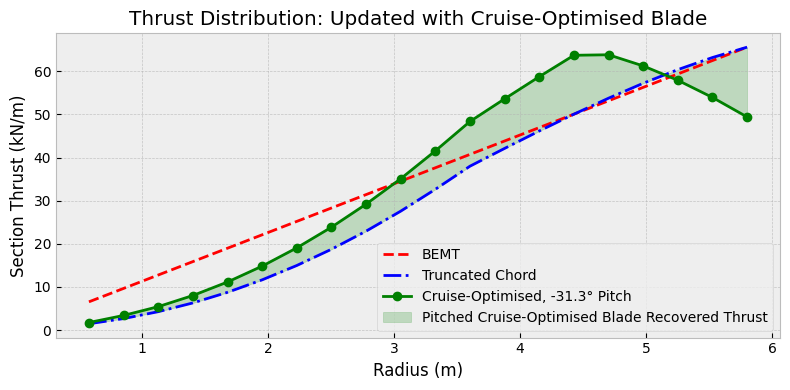

In [93]:
def prop_design_hover(T_max, D, blades=3, alpha_deg=5.0, Cl = 1.1):
    R = D / 2
    A = np.pi * R ** 2
    a = 340 # speed of sound
    v_tip = 0.7 * a
    rho = 1.2
    print(v_tip)

    n_rps = v_tip / (np.pi * D)
    n_rpm = n_rps * 60
    
    # calculating downwash velocity to calculate blade angle addition factor, phi
    # based on momentum equation, T = 0.5 rho A v^2
    v_i = np.sqrt(T_max / (2 * rho * A))
    r_stations = np.linspace(0.1 * R, R, 20)
    v_t = 2 * np.pi * n_rps * r_stations
    phi = np.arctan(v_i / v_t)

    # alpha = AoA of root, beta = AoA of tip
    alpha_rad = np.radians(alpha_deg)
    beta_rad = phi + alpha_rad
    beta_deg = np.degrees(beta_rad)

    # W is relative velocity in each stations
    # blade calculation using Blade Element Momentum Theory
    W = np.sqrt(v_i ** 2 + v_t **2)
    psi = np.arctan(v_i / v_t)
    chord_ideal = (8 * np.pi * r_stations * v_i **2) / (blades * W**2 * Cl * np.cos(psi))

    # taking the 75% radius as a reference station, as significant portion of the thrust
    # is from the outer 25% of the blade, and finally linearising the taper
    idx_75 = np.argmin(np.abs(r_stations - 0.75*R))
    chord_75 = chord_ideal[idx_75]
    chord_tip = chord_ideal[-1]
    slope = (chord_tip - chord_75) / (r_stations[-1] - r_stations[idx_75])

    chord_real = slope * (r_stations - r_stations[-1]) + chord_tip
    chord_real = np.minimum(chord_real, 0.85)

    # taking the integral to calculate the force through the blade
    dT_ideal = blades * 0.5 * rho * W**2 * chord_ideal * Cl * np.cos(phi)
    dT_real = blades * 0.5 * rho * W**2 * chord_real * Cl * np.cos(phi)

    T_ideal = simpson(dT_ideal, x=r_stations) # taking the integrals
    T_real = simpson(dT_real, x=r_stations)
    T_loss = T_ideal - T_real
    T_loss_pct = (T_loss / T_ideal) * 100

    print("\n--- Main Propeller Design ---")
    print(f"Prop Diameter: {D:.2f} m")
    print(f"Single Engine Failure RPM: {n_rpm:.0f} RPM")
    print(f"Induced Wash (v_i): {v_i:.2f} m/s")
    print(f"Max Tip Speed:  {v_tip:.1f} m/s (Mach 0.7)")
    print(f"Root Chord, Ideal:     {chord_ideal[0]:.3f} m")
    print(f"Root Chord, Real:     {chord_real[0]:.3f} m")
    print(f"Tip Chord, Ideal:      {chord_ideal[-1]:.3f} m")
    print(f"Tip Chord, Real:      {chord_real[-1]:.3f} m")

    print("\n--- Forward Integration Results ---")
    print(f"Target Thrust:      {T_max/1000:.1f} kN")
    print(f"Ideal Blade Thrust: {T_ideal/1000:.1f} kN")
    print(f"Practical Thrust:   {T_real/1000:.1f} kN")
    print(f"Thrust Penalty:     {T_loss/1000:.1f} kN ({T_loss_pct:.2f}%)")

    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(8, 8), sharex=True)

    ax1.plot(r_stations, chord_ideal, 'r--', linewidth=2, label='BEMT Chord')
    ax1.plot(r_stations, chord_real, 'b-', linewidth=2, label='Truncated Chord')
    ax1.set_ylabel('Required Chord Width (m)', color='black')
    ax1.tick_params(axis='y', labelcolor='black')
    ax1.grid(True, linestyle='--', alpha=0.7)

    ax1_twin = ax1.twinx()
    ax1_twin.plot(r_stations, beta_deg, 'g-o', linewidth=2, label='Twist Angle')
    ax1_twin.set_ylabel('Twist Angle, Beta (°)', color='green')
    ax1_twin.tick_params(axis='y', labelcolor='green')

    ax1.set_title(f'Chord and Twist Distribution')
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax1_twin.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='best')

    ax2.plot(r_stations, dT_ideal / 1000, 'r--', label='BEMT')
    ax2.plot(r_stations, dT_real / 1000, 'b-', linewidth=2, label='Truncated Chord')
    ax2.fill_between(r_stations, dT_ideal / 1000, dT_real / 1000, color='red', alpha=0.2, label='Lost Thrust vs Ideal')
    ax2.set_xlabel('Radius (m)')
    ax2.set_ylabel('Section Thrust (kN/m)')
    ax2.set_title('Thrust Distribution')
    ax2.grid(True, linestyle='--', alpha=0.7)
    ax2.legend(loc='best')

    plt.tight_layout()
    plt.show()

    results_dict = {"Stations Radius:" : r_stations,
                    "Station Twist Angle:" : beta_deg,
                    "Station Chord Length:" :chord_real}
    return results_dict

def prop_design_mission(D, altitude, condition, v_inf, blades=3, alpha_deg=5.0, hover_results=None):
    R = D/2
    P, T, rho = ISA_atmosphere(altitude)
    a = np.sqrt(1.4 * 287.0 * T)
    v_tip = 0.7 * a

    if v_inf >= v_tip:
        raise ValueError("Forward Speed > Max Tip Mach Number")
    
    n_rps = np.sqrt(v_tip ** 2 - v_inf ** 2) / (np.pi * D)
    n_rpm = n_rps * 60
    r_stations = np.linspace(0.1 * R, R, 20)
    v_t = 2 * np.pi * n_rps * r_stations
    phi = np.arctan(v_inf / v_t)

    alpha = np.radians(alpha_deg)
    beta_rad = phi + alpha
    beta_deg = np.degrees(beta_rad)

    print(f"\n--- {condition} Propeller Design ({altitude} m) ---")
    print(f"Target V_inf:      {v_inf:.1f} m/s (Mach {v_inf/a:.3f})")
    print(f"{condition} RPM:   {n_rpm:.0f} RPM (Reduced from Hover to keep Mach 0.7)")
    print(f"Total Tip Speed:   {v_t[-1]:.1f} m/s (Mach {v_t[-1]/a})")
    print(f"Air Density:       {rho:.3f} kg/m^3")

    if hover_results is not None:
        beta_hover = hover_results['Station Twist Angle:']
        idx_75 = np.argmin(np.abs(r_stations - 0.75 * R))
        shift_ang = (beta_hover[idx_75] - beta_deg[idx_75]).item()

        print("\n--- Variable Pitch Mechanism ---")
        print(f"75% Station Cruise Angle: {beta_deg[idx_75]:.1f} deg")
        print(f"75% Station Hover Angle:  {beta_hover[idx_75]:.1f} deg")
        print(f"Required Pitch Shift: {shift_ang:.1f} degrees ({condition} -> Hover)")
        
    #     plt.figure(figsize=(8, 4))
    #     plt.plot(r_stations, beta_deg, 'g-o', label=f'{condition} Angle')
    #     plt.plot(r_stations, beta_hover, 'b--x', alpha=0.6, label='Ideal Hover Angle')
        
    #     rotated_manufactured_blade = beta_deg + shift_ang
    #     plt.plot(r_stations, rotated_manufactured_blade, 'r-', linewidth=2, label=f'{condition} {shift_ang:.1f}°, for Hover)')
        
    #     plt.xlabel('Radius (m)')
    #     plt.ylabel('Variable Pitch Angle (degrees)')
    #     plt.title(f'Variable Pitch: {condition} vs. Hover')
    #     plt.grid(True, linestyle='--', alpha=0.7)
    #     plt.legend()
    #     plt.show()

    else:
        pass
    
    results_dict = {"Twist Angle (Deg):" : beta_deg}
    
    return results_dict, n_rpm, shift_ang

def evaluate_manufactured_hover(T_max, D, hover_results, cruise_results, shift_ang, blades=3):
    r_stations = hover_results["Stations Radius:"]
    chord_real = hover_results["Station Chord Length:"]
    beta_cruise = cruise_results["Twist Angle (Deg):"]
    
    # Hover Kinematics
    rho = 1.2
    R = D / 2
    A = np.pi * R ** 2
    a = 340 
    v_tip = 0.7 * a
    n_rps = v_tip / (np.pi * D)
    
    v_i = np.sqrt(T_max / (2 * rho * A))
    v_t = 2 * np.pi * n_rps * r_stations
    phi = np.arctan(v_i / v_t)
    W = np.sqrt(v_i ** 2 + v_t **2)
    
    psi = np.arctan(v_i / v_t)
    chord_ideal = (8 * np.pi * r_stations * v_i **2) / (blades * W**2 * 1.1 * np.cos(psi))
    beta_mfg = beta_cruise + shift_ang
    alpha_rad_mfg = np.radians(beta_mfg) - phi
    alpha_deg_mfg = np.degrees(alpha_rad_mfg)

    # clipping Cl values
    Cl_mfg = 0.11 * (alpha_deg_mfg + 5.0)
    Cl_mfg = np.clip(Cl_mfg, -0.2, 1.4) 

    # taking the spanwise integral for thrust
    dT_ideal = blades * 0.5 * rho * W**2 * chord_ideal * 1.1 * np.cos(phi)
    dT_trunc = blades * 0.5 * rho * W**2 * chord_real * 1.1 * np.cos(phi)
    dT_mfg = blades * 0.5 * rho * W**2 * chord_real * Cl_mfg * np.cos(phi)
    T_ideal = simpson(dT_ideal, x=r_stations)
    T_trunc = simpson(dT_trunc, x=r_stations)
    T_mfg = simpson(dT_mfg, x=r_stations)

    loss_trunc_pct = ((T_ideal - T_trunc) / T_ideal) * 100
    loss_mfg_pct = ((T_ideal - T_mfg) / T_ideal) * 100
    additional_twist_penalty = loss_mfg_pct - loss_trunc_pct

    print("\n--- Final OEI Hover Aerodynamic Evaluation ---")
    print(f"Target Thrust:                 {T_max/1000:.1f} kN")
    print(f"1. Ideal BEMT Thrust:     {T_ideal/1000:.1f} kN")
    print(f"2. Target Twist Angle:  {T_trunc/1000:.1f} kN (-{loss_trunc_pct:.1f}% loss)")
    print(f"3. Cruise Twist Angle + Pitch:   {T_mfg/1000:.1f} kN (-{loss_mfg_pct:.1f}% total loss)")
    print(f"-> Penalty solely from twist mismatch: {additional_twist_penalty:.1f}%")

    plt.figure(figsize=(8, 4))
    plt.plot(r_stations, dT_ideal / 1000, 'r--', linewidth=2, label='BEMT')
    plt.plot(r_stations, dT_trunc / 1000, 'b-.', linewidth=2, label='Truncated Chord')
    plt.plot(r_stations, dT_mfg / 1000, 'g-o', linewidth=2, label=f'Cruise-Optimised, {shift_ang}° Pitch')
    plt.fill_between(r_stations, dT_trunc / 1000, dT_mfg / 1000, color='green', alpha=0.2, label='Pitched Cruise-Optimised Blade Recovered Thrust')
    
    plt.xlabel('Radius (m)')
    plt.ylabel('Section Thrust (kN/m)')
    plt.title('Thrust Distribution: Updated with Cruise-Optimised Blade')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
hover = prop_design_hover(thrust_maximum, 11.6)
cruise_twist, cruise_RPM, cruise_shift = prop_design_mission(prop_diameter, 3000, "Cruise", v_inf=cruise_speed, hover_results=hover)
search_twist, search_RPM, search_shift = prop_design_mission(prop_diameter, 150, "Search", v_inf=search_speed, hover_results=hover)

# hover, cruise_twist, search_twist, cruise_RPM, search_RPM, evaluate_manufactured_hover(thrust_maximum, prop_diameter, hover, cruise_twist, cruise_shift)
evaluate_manufactured_hover(thrust_maximum, prop_diameter, hover, cruise_twist, -31.3)

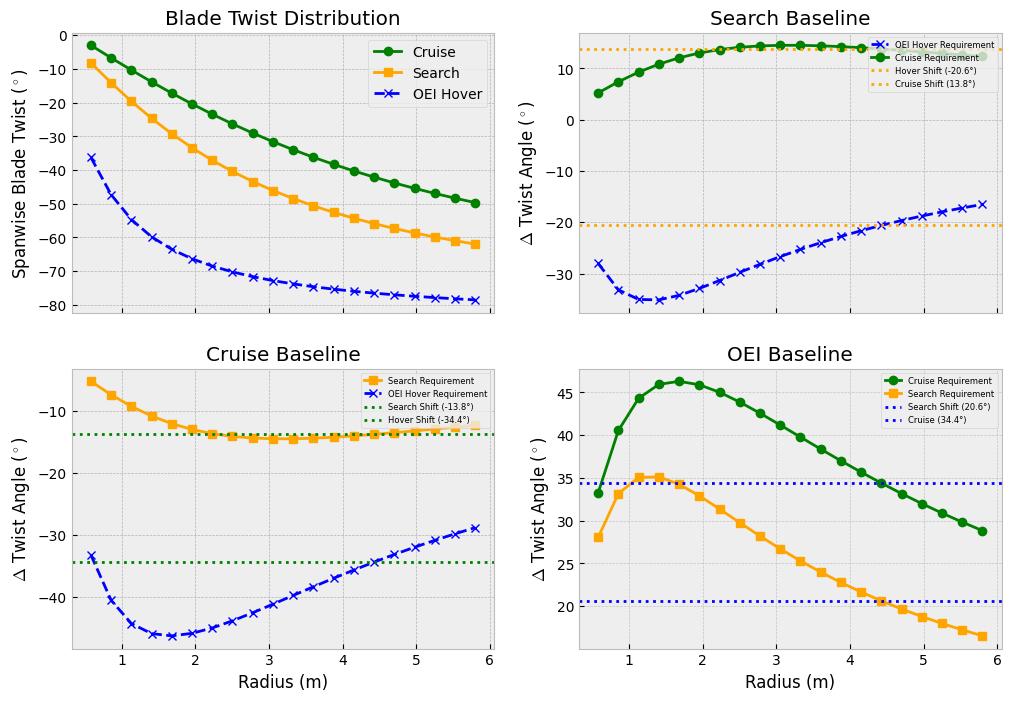

In [90]:
r_stations = hover["Stations Radius:"]
idx_75 = np.argmin(np.abs(r_stations - 0.75 * prop_diameter / 2))

beta_hover = hover["Station Twist Angle:"]
beta_cruise = cruise_twist["Twist Angle (Deg):"]
beta_search = search_twist["Twist Angle (Deg):"]

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12, 8), sharex=True)
# Baseline Requirements
ax[0,0].plot(r_stations, beta_cruise - 90, 'g-o', linewidth=2, label='Cruise')
ax[0,0].plot(r_stations, beta_search - 90, 'orange', marker='s', linewidth=2, label='Search')
ax[0,0].plot(r_stations, beta_hover - 90, 'b--x', linewidth=2, label='OEI Hover')

ax[0,0].set_ylabel(r'Spanwise Blade Twist ($^\circ$)')
ax[0,0].set_title('Blade Twist Distribution')
ax[0,0].legend()

# Cruise Baselining
delta_hc = beta_hover - beta_cruise
delta_sc = beta_search - beta_cruise
search_shift = delta_sc[idx_75]
hover_shift = delta_hc[idx_75]

# ax2.plot(r_stations, beta_cruise - beta_cruise, 'g-o', linewidth=2, label='Cruise, Zero Variable Pitch')
ax[1,0].plot(r_stations, delta_sc, 'orange', marker='s', linewidth=2, label='Search Requirement')
ax[1,0].plot(r_stations, delta_hc, 'b--x', linewidth=2, label='OEI Hover Requirement')
ax[1,0].axhline(y=search_shift, color='green', linestyle=':', linewidth=2, label=f'Search Shift ({search_shift:.1f}°)')
ax[1,0].axhline(y=hover_shift, color='green', linestyle=':', linewidth=2, label=f'Hover Shift ({hover_shift:.1f}°)')
ax[1,0].set_xlabel('Radius (m)')
ax[1,0].set_ylabel(r'$\Delta$ Twist Angle ($^\circ$)')
ax[1,0].set_title('Cruise Baseline')
ax[1,0].legend(loc='upper right',prop={'size': 6})

# Search Baselining
delta_hs = beta_hover - beta_search
delta_cs = beta_cruise - beta_search
cruise_shift = delta_cs[idx_75]
hover_shift = delta_hs[idx_75]

# ax3.plot(r_stations, beta_search - beta_search, 'orange', marker='s', linewidth=2, label='Search, Zero Variable Pitch')
ax[0,1].plot(r_stations, delta_hs, 'b--x', linewidth=2, label='OEI Hover Requirement')
ax[0,1].plot(r_stations, delta_cs, 'g-o', linewidth=2, label='Cruise Requirement')
ax[0,1].axhline(y=hover_shift, color='orange', linestyle=':', linewidth=2, label=f'Hover Shift ({hover_shift:.1f}°)')
ax[0,1].axhline(y=cruise_shift, color='orange', linestyle=':', linewidth=2, label=f'Cruise Shift ({cruise_shift:.1f}°)')
ax[0,1].set_ylabel(r'$\Delta$ Twist Angle ($^\circ$)')
ax[0,1].set_title('Search Baseline')
ax[0,1].legend(loc='upper right',prop={'size': 6})

# Hover Baselining
delta_ch = beta_cruise - beta_hover
delta_sh = beta_search - beta_hover
cruise_shift = delta_ch[idx_75]
search_shift = delta_sh[idx_75]

# ax4.plot(r_stations, beta_hover - beta_hover, 'b--x', linewidth=2, label='OEI, Zero Variable Pitch')
ax[1,1].plot(r_stations, delta_ch, 'g-o', linewidth=2, label='Cruise Requirement')
ax[1,1].plot(r_stations, delta_sh, 'orange', marker='s', linewidth=2, label='Search Requirement')
ax[1,1].axhline(y=search_shift, color='blue', linestyle=':', linewidth=2, label=f'Search Shift ({search_shift:.1f}°)')
ax[1,1].axhline(y=cruise_shift, color='blue', linestyle=':', linewidth=2, label=f'Cruise ({cruise_shift:.1f}°)')
ax[1,1].set_xlabel('Radius (m)')
ax[1,1].set_ylabel(r'$\Delta$ Twist Angle ($^\circ$)')
ax[1,1].set_title('OEI Baseline')
ax[1,1].legend(loc='upper right',prop={'size': 6})

plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


In [24]:
naca_4412_norm = """1.0000     0.0013
0.9500     0.0147
0.9000     0.0271
0.8000     0.0489
0.7000     0.0669
0.6000     0.0814
0.5000     0.0919
0.4000     0.0980
0.3000     0.0976
0.2500     0.0941
0.2000     0.0880
0.1500     0.0789
0.1000     0.0659
0.0750     0.0576
0.0500     0.0473
0.0250     0.0339
0.0125     0.0244
0.0000     0.0000
0.0125     -0.0143
0.0250     -0.0195
0.0500     -0.0249
0.0750     -0.0274
0.1000     -0.0286
0.1500     -0.0288
0.2000     -0.0274
0.2500     -0.0250
0.3000     -0.0226
0.4000     -0.0180
0.5000     -0.0140
0.6000     -0.0100
0.7000     -0.0065
0.8000     -0.0039
0.9000     -0.0022
0.9500     -0.0016
1.0000     -0.0013"""

coords = np.array([list(map(float, line.split())) for line in naca_4412_norm.strip().split('\n')])
x_norm = coords[:, 0]
y_norm = coords[:, 1]

r_stations = hover['Stations Radius:']
beta_deg = cruise_twist["Twist Angle (Deg):"]
chord_length = hover['Station Chord Length:']

# beta_hover = hover["Station Twist Angle:"]
# beta_cruise = cruise_twist["Twist Angle (Deg):"]
# beta_search = search_twist["Twist Angle (Deg):"]

output_dir = 'airfoil_coord_cruise'
os.makedirs(output_dir, exist_ok=True)

for i in range(len(r_stations)):
    r = r_stations[i]
    c = chord_length[i]
    beta = np.radians(beta_deg[i])

    x_scaled = (x_norm * c) - (0.25 * c)
    y_scaled = (y_norm * c)

    x_3d = x_scaled * np.cos(-beta) - y_scaled * np.sin(-beta)
    y_3d = x_scaled * np.sin(-beta) + y_scaled * np.cos(-beta)
    z_3d = np.full_like(x_3d, r)

    filename = f"{output_dir}/station_{i+1:02d}_r{r:.2f}.csv"

    with open(filename, 'w') as f:
        for j in range(len(x_3d)):
            f.write(f"{x_3d[j]:.6f},{y_3d[j]:.6f},{z_3d[j]:.6f}\n")

    print(f'Generated {filename}')


Generated airfoil_coord_cruise/station_01_r0.58.csv
Generated airfoil_coord_cruise/station_02_r0.85.csv
Generated airfoil_coord_cruise/station_03_r1.13.csv
Generated airfoil_coord_cruise/station_04_r1.40.csv
Generated airfoil_coord_cruise/station_05_r1.68.csv
Generated airfoil_coord_cruise/station_06_r1.95.csv
Generated airfoil_coord_cruise/station_07_r2.23.csv
Generated airfoil_coord_cruise/station_08_r2.50.csv
Generated airfoil_coord_cruise/station_09_r2.78.csv
Generated airfoil_coord_cruise/station_10_r3.05.csv
Generated airfoil_coord_cruise/station_11_r3.33.csv
Generated airfoil_coord_cruise/station_12_r3.60.csv
Generated airfoil_coord_cruise/station_13_r3.88.csv
Generated airfoil_coord_cruise/station_14_r4.15.csv
Generated airfoil_coord_cruise/station_15_r4.43.csv
Generated airfoil_coord_cruise/station_16_r4.70.csv
Generated airfoil_coord_cruise/station_17_r4.98.csv
Generated airfoil_coord_cruise/station_18_r5.25.csv
Generated airfoil_coord_cruise/station_19_r5.53.csv
Generated ai

In [ ]:
### Horizontal Takeoff ###

In [ ]:
### Search ###
# high air density, low V

In [ ]:
### Hover ###
# high  air density, V = 0